# Micrograd: Building a Neural Network From Scratch

This notebook follows Andrej Karpathy's lecture **"The spelled-out intro to neural networks and backpropagation: building micrograd"**.

**micrograd** is a tiny *autograd* (automatic gradient) engine. It does, for single numbers (scalars), exactly what PyTorch does for big tensors: it remembers how every number was computed, and then works out **how much each input affected the final output** (the *gradient*). That is all you need to train a neural network.

### Roadmap

| Part | What we do | Key idea |
|---|---|---|
| 1 | Derivatives of simple functions | A derivative = "if I nudge the input a tiny bit, how much does the output move?" |
| 2 | The `Value` class | Wrap numbers so they remember *where they came from* (a computation graph) |
| 3 | Manual backpropagation | Use the **chain rule** to compute gradients node by node, from the output backwards |
| 4 | A single neuron | Weighted sum + bias + `tanh` activation, backpropagated by hand |
| 5 | Automating backprop | `_backward()` per node, then `backward()` with a topological sort |
| 6 | Comparing with PyTorch | Same numbers, same gradients |
| 7 | A neural network library | `Neuron` → `Layer` → `MLP` |
| 8 | Training | Forward pass → loss → backward pass → update, repeated (gradient descent) |

In [45]:
# Importing the essential libraries
import math                      # math.tanh / math.exp: work on plain Python floats (used inside the Value class)
import numpy as np               # fast arrays: lets us evaluate a function on many inputs at once for plotting
import matplotlib.pyplot as plt  # plotting

---
# Part 1: What is a derivative?

Before building anything, we need a feel for what a derivative *means*. Forget the rules from school (power rule etc.) for a second. The derivative of a function at a point answers one question:

> **If I increase the input by a tiny amount `h`, by how much (and in which direction) does the output change?**

- Positive derivative: output goes **up** when the input goes up.
- Negative derivative: output goes **down** when the input goes up.
- Zero derivative: output (momentarily) doesn't change; we're at a flat spot (e.g. the bottom of a valley).

Neural network training is nothing more than using this information to nudge millions of inputs (the weights) in the direction that makes the error go down.

In [46]:
# Defining a simple test function so we can study derivatives
# f(x) = 3x^2 - 4x + 5   (a parabola that opens upwards)
def hyperbola(x):
    return 3*x**2 - 4*x + 5

hyperbola(3.0)  # 3*9 - 12 + 5 = 20.0

20.0

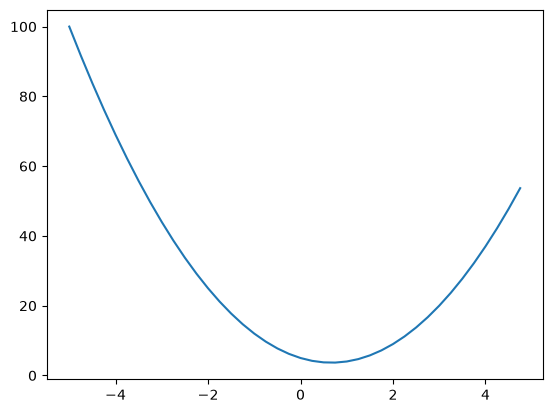

In [47]:
# Plotting the function for a set of evenly spaced inputs
xs = np.arange(-5, 5, 0.25)  # [-5.0, -4.75, ..., 4.75]: 40 points
ys = hyperbola(xs)                   # works element-wise because xs is a numpy array (no loop needed)
plt.plot(xs, ys)

**Reading the plot:** it's a U-shaped parabola.
- On the **left** side the curve slopes *down*, so the derivative there is **negative**.
- On the **right** side it slopes *up*, so the derivative is **positive**.
- At the very **bottom** (which happens at $x = 2/3$) the curve is flat, so the derivative is **0**.

From calculus we know $f'(x) = 6x - 4$. But micrograd will never use these symbolic formulas for whole functions; we'll compute derivatives numerically first, to build intuition.

### Calculating the derivative numerically, using the limit definition of a derivative:

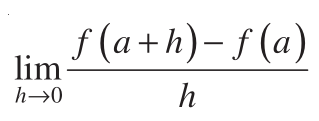

**In words:** take the function value at `a + h`, subtract the value at `a`, and divide by `h`.
- The numerator is *how much the output changed*.
- Dividing by `h` turns that into a *rate*: change in output **per unit** change in input (i.e., the slope).
- The formula is exact only in the limit $h \to 0$. On a computer we just pick a very small `h` (like `0.000001`) and get a very good approximation.

In [ ]:
# h: a tiny nudge to the input (close to zero, but not so small that floating-point errors take over)
h = 0.000001
# x: the point at which we want the slope. 2/3 is the bottom of the parabola
x = 2/3
# derivative: numerical derivative of f at x, i.e. (change in output) / (change in input)
derivative = (hyperbola(x + h) - hyperbola(x)) / h
derivative  # ~0, because the parabola is flat at its minimum

2.999378523327323e-06

The result is about `0.000003`, essentially **zero**, as expected at the bottom of the curve. (It's not exactly 0 because `h` isn't infinitely small: for this function the error is $3h$.)

Try changing `x` yourself:
- `x = 3.0` gives ≈ `14` (= 6·3 − 4): steep upward slope.
- `x = -3.0` gives ≈ `-22`: steep downward slope.

### Derivatives with multiple inputs

Now a slightly more interesting function with **three** inputs: `fx = a*b + c`.

With several inputs we can ask the derivative question *separately for each one*: "if I nudge only `a` (keeping `b` and `c` fixed), how does the output change?" This is called a **partial derivative**, written $\frac{\partial f}{\partial a}$.

In [49]:
h = 0.000001

# inputs
a = 2.0
b = -3.0
c = 10.0

fx = a*b+c   # output before the nudge: 2*(-3) + 10 = 4.0
a += h       # nudge ONLY `a` by a tiny amount
d2 = a*b+c   # output AFTER the nudge (this is a function value, not the derivative itself)

print("fx", fx)
print("d2", d2)
# slope = (change in output) / (change in input) = partial derivative of fx w.r.t. a
# Result is -3.0 (which is exactly b): increasing `a` makes the output go DOWN, 3x as fast.
print("slope", (d2 - fx) / h)

fx 4.0
d2 3.9999969999999996
slope -3.000000000419334


**Why is the slope exactly `b` (= −3)?** Because `a` is multiplied by `b`. If `a` increases by `h`, then `a*b` changes by `b*h`, and dividing by `h` leaves `b`.

By the same logic (try it by nudging `b` or `c` instead of `a`):
- $\frac{\partial f}{\partial b} = a = 2$ (nudging `b` makes the output go **up**, 2× as fast)
- $\frac{\partial f}{\partial c} = 1$ (`c` is just added, so it passes straight through)

Keep these two patterns in mind, because they are the whole of backpropagation for `+` and `*`:
- **Multiplication:** the derivative w.r.t. one input is **the other input**.
- **Addition:** the derivative w.r.t. each input is **1**.

---
# Part 2: The `Value` class (the heart of micrograd)

Neural networks are big mathematical expressions. To compute gradients automatically, every number needs to **remember how it was created**. So instead of plain floats we wrap each number in a `Value` object.

### What each `Value` stores

| Attribute | Meaning |
|---|---|
| `data` | the actual number (e.g. `2.0`) |
| `grad` | the derivative of the **final output** w.r.t. this value, i.e. $\frac{\partial L}{\partial \text{this}}$. Starts at `0.0` ("no effect yet"). |
| `_prev` | the `Value`s this one was computed **from** (its "children" in the graph) |
| `_op` | the operation that produced it (`'+'`, `'*'`, `'tanh'`, …), used only for drawing |
| `label` | a human-readable name, used only for drawing |
| `_backward` | a small function that knows how to push this node's gradient **back** to its children |

### How the operators work

Python lets a class define what `+`, `*`, `-`, `/`, `**` mean via "dunder" (double underscore) methods. When you write `a * b` with two `Value`s, Python calls `a.__mul__(b)`, which:
1. **Forward pass:** computes the new number `a.data * b.data` and wraps it in a new `Value` (`out`), recording `(a, b)` as its children.
2. **Prepares the backward pass:** defines a `_backward` function that, when called later, applies the chain rule:

$$\text{child.grad} \mathrel{+}= \underbrace{\frac{\partial\, \text{out}}{\partial\, \text{child}}}_{\text{local derivative}} \times \underbrace{\text{out.grad}}_{\text{gradient flowing in from above}}$$

Every operation only needs to know its own **local derivative**:

| Operation | Local derivative(s) |
|---|---|
| `out = a + b` | ∂out/∂a = 1, ∂out/∂b = 1 |
| `out = a * b` | ∂out/∂a = b, ∂out/∂b = a |
| `out = tanh(a)` | ∂out/∂a = 1 − tanh(a)² = 1 − out² |
| `out = exp(a)` | ∂out/∂a = exp(a) = out |
| `out = a ** k` | ∂out/∂a = k · a^(k−1) |

### Why `+=` and not `=` in `_backward`?

If a value is used **more than once** (e.g. `b = a + a`, or a weight feeding several things), gradient arrives from **each** use, and the total effect is the **sum** of all of them (the multivariable chain rule). Using `=` would overwrite earlier contributions and give wrong answers. This is also why gradients must be **reset to zero** before each new backward pass during training.

Don't worry if `backward()` (the method at the bottom) isn't clear yet; it's explained in detail in Part 5. Parts 3 and 4 do everything by hand first.

In [50]:
class Value:
    # Stores a single scalar value plus everything needed to compute its gradient.
    def __init__(
        self, data, _children=(), _op="", label="", grad=0.0, _backward=lambda: None
    ):
        self.data = data              # the actual number
        self._prev = set(_children)   # the Values this one was made from (empty for inputs/leaf nodes)
        self._op = _op                # the operation that created this Value ('+', '*', 'tanh', ...)
        self.label = label            # optional name, shown in the graph drawing
        self.grad = grad              # dL/d(this value); 0.0 means "no effect on the output (yet)"
        self._backward = _backward    # function that propagates self.grad to the children.
                                      # Leaf nodes (inputs) have nothing to propagate to, so the default does nothing.

    def __repr__(self):
        # What gets printed when you display a Value in a cell
        return f"Value(data={self.data}, label={self.label})"

    # ---------------------------------------------------------------- addition
    def __add__(self, other):  # called for: self + other
        # Allow `Value + 2.0` by wrapping plain numbers in a Value
        other = other if isinstance(other, Value) else Value(other)
        # Forward pass: compute the sum and remember both inputs as children
        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            # Local derivative of a sum w.r.t. each input is 1,
            # so '+' simply passes the incoming gradient through to both inputs unchanged.
            self.grad += out.grad
            other.grad += out.grad

        out._backward = _backward  # attach the function to the OUTPUT node; it is called later during backprop
        return out

    def __radd__(self, other):  # called for: other + self, when `other` is a plain number (e.g. 2 + Value)
        # Addition is commutative, so just reuse __add__.
        # Also needed for Python's built-in sum(), which starts from 0 and does 0 + Value.
        return self + other

    def __neg__(self):  # called for: -self
        return self * -1  # negation is just multiplication by -1 (so we reuse __mul__ and its gradient)

    def __sub__(self, other):  # called for: self - other
        return self + (-other)  # subtraction = adding the negative (reuses __add__ and __neg__)

    # ---------------------------------------------------------- multiplication
    def __mul__(self, other):  # called for: self * other
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def _backward():
            # Local derivative of a*b w.r.t. a is b, and w.r.t. b is a,
            # then multiply by out.grad (chain rule).
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def __rmul__(self, other):  # called for: other * self, e.g. 2 * Value
        return self * other

    # ------------------------------------------------------ activation: tanh
    def tanh(self):
        # Forward pass: squash the value into the range (-1, 1)
        out = Value(math.tanh(self.data), (self,), "tanh")

        def _backward():
            # d/dx tanh(x) = 1 - tanh(x)^2, and tanh(x) is already stored in out.data
            self.grad += (1 - out.data**2) * out.grad

        out._backward = _backward
        return out

    # ------------------------------------------------------------ exponential
    def exp(self):
        out = Value(math.exp(self.data), (self,), "exp")

        def _backward():
            # d/dx e^x = e^x, which is exactly out.data
            self.grad += out.data * out.grad

        out._backward = _backward
        return out

    # ------------------------------------------------------------------ power
    def __pow__(self, other):  # called for: self ** other
        # Only plain-number exponents are supported (e.g. x**2, x**-1), not Value exponents
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f"**{other}")

        def _backward():
            # Power rule: d/dx x^n = n * x^(n-1)
            self.grad += other * self.data ** (other - 1) * out.grad

        out._backward = _backward
        return out

    def __truediv__(self, other):  # called for: self / other
        # Division rewritten as multiplication by a power: a / b = a * b**-1
        # (reuses __mul__ and __pow__, so no new derivative formula is needed)
        return self * other**-1

    # ------------------------------------------------------ full backpropagation
    def backward(self):
        # Computes the gradient of THIS value (normally the loss L) w.r.t. every Value in its graph.

        # Step 1: Topological sort. Order the nodes so that every node comes AFTER all of its children.
        # Reversed, this guarantees that a node's gradient is completely finished
        # before we push it further back to its own children.
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:          # each node is processed only once
                visited.add(v)
                for child in v._prev:     # first visit all children (depth-first) ...
                    build_topo(child)
                topo.append(v)            # ... then add the node itself

        build_topo(self)

        # Step 2: The derivative of the output w.r.t. itself is 1 (dL/dL = 1). This is the starting point.
        self.grad = 1.0
        # Step 3: Walk from the output back to the inputs, applying each node's local chain-rule step.
        for node in reversed(topo):
            node._backward()


# ------------------------------------------------------------------------------
# Build a small expression using Value objects:  L = (a*b + c) * f
# Each intermediate result gets a label so the graph drawing is readable.
a = Value(2.0, label="a")
b = Value(-3.0, label="b")
c = Value(10.0, label="c")
e = a * b            # e = -6.0
e.label = "e"
d = e + c            # d =  4.0
d.label = "d"
f = Value(-2.0, label="f")
L = d * f            # L = -8.0  (think of L as our "loss": the final output)
L.label = "L"

### Visualizing the computation graph

These two helper functions draw the expression as a graph using **graphviz**:
- `trace(root)` walks backwards from the output through every `_prev` link and collects all **nodes** (Values) and **edges** (child → parent connections).
- `draw_dot(root)` draws each Value as a box showing `label | data | grad`, plus a small circle for the operation that produced it.

In [51]:
from graphviz import Digraph

def trace(root):
    # Collect every node and edge reachable from `root` by following _prev (children) links
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))  # an arrow from the input (child) to the result (v)
                build(child)           # recurse into the child's own inputs
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = draw left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))  # id() gives a unique number for each Python object, used as the node name
        # A "record" box for each Value: | label | data | grad |
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # If this Value came from an operation, draw an extra small node for the op ('+', '*', ...)
            dot.node(name = uid + n._op, label=n._op)
            # and connect: op node -> result Value
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect: input Value -> op node of the result
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

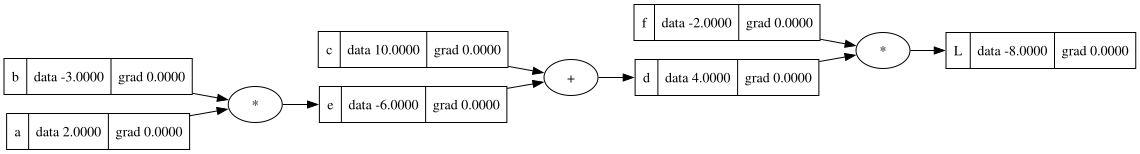

In [52]:
draw_dot(L)

**How to read this:** data flows **left to right** (this is the *forward pass*). `a` and `b` are multiplied to give `e`, `e` and `c` are added to give `d`, and `d` and `f` are multiplied to give `L = -8`.

Every `grad` is currently **0**, because we haven't done any backpropagation yet. Next, we'll fill them in by hand, going **right to left**.

---
# Part 3: Manual backpropagation (chain rule)

**Goal:** for every node `x` in the graph, find `x.grad` $= \frac{\partial L}{\partial x}$, i.e. *"if I nudge `x` a tiny bit, how much does the final output `L` change?"*

We start at the output and walk **backwards** (right to left in the graph). At each node we only need two things:
1. the gradient already computed for the node **above** it (closer to `L`), and
2. the **local derivative** of the operation connecting them.

Multiply them together and you get the gradient for the node below. That's the **chain rule**, and that's all backpropagation is.

In [53]:
# Base case: the derivative of L with respect to itself is 1
# (if you nudge L by h, L changes by h, so the ratio is 1)
L.grad = 1.0

### Gradient of `d` and `f`

We have $L = d \cdot f$. What is $\frac{\partial L}{\partial d}$?

Use the limit definition, nudging only `d` by `h` (careful: here `f` is the **variable** `f = -2`, not the function from Part 1):

$$\frac{\partial L}{\partial d} = \frac{(d+h)\cdot f - d \cdot f}{h} = \frac{d\cdot f + h\cdot f - d \cdot f}{h} = \frac{h \cdot f}{h} = f$$

So $\frac{\partial L}{\partial d} = f = -2$, and by symmetry $\frac{\partial L}{\partial f} = d = 4$.

This is the **multiplication rule** from Part 1: the gradient of one input is the *other* input (times the gradient coming from above, which here is `L.grad = 1`).

In [54]:
d.grad = L.grad * f.data  # 1 * -2 = -2   (local derivative of d*f w.r.t. d is f)
f.grad = L.grad * d.data  # 1 *  4 =  4   (local derivative of d*f w.r.t. f is d)

### Gradient of `c` and `e`: the chain rule

`c` and `e` don't touch `L` directly; they first create `d = c + e`, and then `d` affects `L`. So how does `c` influence `L`?

**Chain rule:** multiply the rates along the path.

$$\frac{\partial L}{\partial c} = \frac{\partial L}{\partial d} \cdot \frac{\partial d}{\partial c}$$

Intuition (from the lecture): *if a car travels twice as fast as a bicycle, and the bicycle is four times as fast as a walking man, then the car is 2 × 4 = 8 times as fast as the man.* Rates of change multiply.

- We already know $\frac{\partial L}{\partial d} = -2$.
- Local derivative: $d = c + e$, so $\frac{\partial d}{\partial c} = 1$ (addition rule).

$$\frac{\partial L}{\partial c} = -2 \times 1 = -2, \qquad \frac{\partial L}{\partial e} = -2 \times 1 = -2$$

**Key insight:** a `+` node just **copies/routes** the gradient from above to all its inputs unchanged.

In [55]:
c.grad = d.grad * 1.0  # -2 * 1 = -2   (a '+' node passes the gradient straight through)
e.grad = d.grad * 1.0  # -2 * 1 = -2

### Gradient of `a` and `b`

$e = a \cdot b$, a multiplication node. Apply the chain rule once more:

$$\frac{\partial L}{\partial a} = \frac{\partial L}{\partial e} \cdot \frac{\partial e}{\partial a} = -2 \cdot b = -2 \cdot (-3) = 6$$

$$\frac{\partial L}{\partial b} = \frac{\partial L}{\partial e} \cdot \frac{\partial e}{\partial b} = -2 \cdot a = -2 \cdot 2 = -4$$

In [56]:
a.grad = 6.0   # = e.grad * b.data = -2 * -3
b.grad = -4.0  # = e.grad * a.data = -2 *  2
# (equivalently: a.grad = e.grad * b.data ; b.grad = e.grad * a.data)

### Summary of all gradients

| Node | data | grad = ∂L/∂node | Meaning |
|---|---|---|---|
| `L` | -8.0 | 1.0 | base case |
| `d` | 4.0 | -2.0 | = f |
| `f` | -2.0 | **4.0** | = d |
| `c` | 10.0 | -2.0 | `+` routes d.grad |
| `e` | -6.0 | -2.0 | `+` routes d.grad |
| `a` | 2.0 | 6.0 | = e.grad × b |
| `b` | -3.0 | -4.0 | = e.grad × a |

(You can re-run `draw_dot(L)` to see them on the graph.)

The **leaf nodes** (`a`, `b`, `c`, `f`) are the inputs we can actually control; in a neural network these would be the weights and biases.

### Using the gradients: nudging the inputs

The sign of each gradient tells us which direction to move an input to make `L` **go up**:
- `a.grad = 6 > 0`: increasing `a` increases `L`.
- `b.grad = -4 < 0`: *decreasing* `b` increases `L`.

So if we move **every** leaf a small step in the direction of its gradient (`data += step_size * grad`), `L` should increase. The cell below does exactly that, re-runs the forward pass, and checks.

In [57]:
# Nudge each leaf a small step (0.01) IN THE DIRECTION of its gradient.
# This should make L go UP (gradient *ascent*).
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

# Re-run the forward pass with the new values
e = a * b
d = e + c
L = d * f

print("L:", L.data)  # was -8.0 before; now about -7.29, so it went up as predicted

L: -7.286496


`L` went from **-8.0** to about **-7.29**: it **increased**, just as the gradients predicted.

> **This is the core idea of training.** When `L` is a *loss* (error) we want it to go **down**, so we step in the **opposite** direction of the gradient: `data -= step_size * grad`. That's **gradient descent**, and you'll see exactly this (`p.data += -0.01 * p.grad`) in the training loop at the end of the notebook.

---
# Part 4: A neuron, backpropagated by hand

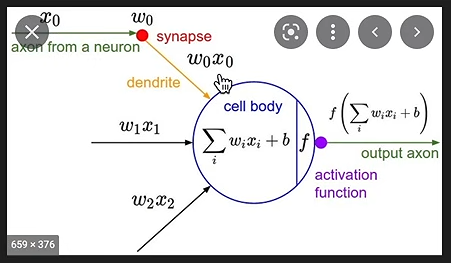

Above is the **mathematical model of a neuron** (loosely inspired by biological neurons):

1. It receives inputs $x_1, x_2, \dots$
2. Each input is multiplied by a **weight** $w_i$ (how strongly that input matters, and whether positively or negatively).
3. Everything is summed up, and a **bias** $b$ is added (a "trigger-happiness" offset, independent of inputs):
$$n = \sum_i w_i x_i + b$$
4. The result is passed through an **activation function**: $\text{out} = \tanh(n)$.

The **weights and bias are the parameters we learn**. During training, backpropagation tells us how to nudge each one to reduce the loss.

**Why an activation function?** Without it, stacking neurons would just produce one big linear function (a weighted sum of weighted sums is still a weighted sum). Non-linear activations like **tanh**, **ReLU** or **sigmoid** let the network bend and represent complex patterns.

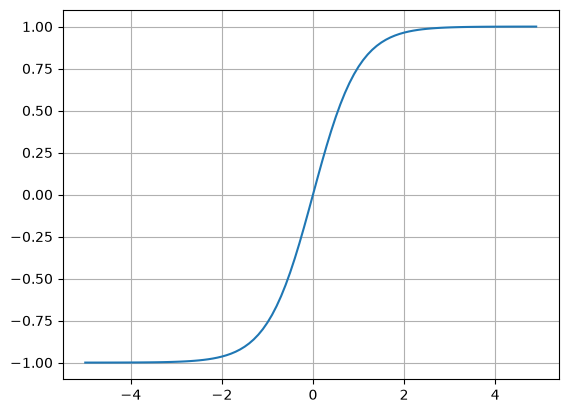

In [58]:
# Plot of the tanh activation function between -5 and 5

plt.plot(np.arange(-5, 5, 0.1), np.tanh(np.arange(-5, 5, 0.1))); plt.grid();

**tanh** squashes any input into the range **(-1, 1)**:
- Near 0 it is almost a straight line (output ≈ input).
- Large positive inputs saturate toward **+1**; large negative inputs toward **-1**.

Its definition:

$$\tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}} = \frac{e^{2x} - 1}{e^{2x} + 1}$$

And its derivative, which we'll need for backprop:

$$\frac{d}{dx}\tanh(x) = 1 - \tanh^2(x)$$

Notice the derivative is close to **0** in the flat (saturated) regions: if a neuron's input is very large, nudging it barely changes the output, so very little gradient flows back through it.

In [59]:
# A single neuron with 2 inputs, built from Value objects so we can backpropagate through it.
# out = tanh(x1*w1 + x2*w2 + b)

# inputs (the data)
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights (one per input; these are learnable parameters)
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of the neuron (also learnable).
# This odd number is chosen on purpose so that n = -6 + 0 + 6.8813... = 0.8813...,
# and tanh(0.8813...) = 0.7071 = 1/sqrt(2). That makes the gradients come out as nice round numbers.
b = Value(6.8813735870195432, label='b')

# Build the expression step by step so every intermediate node has a label in the graph
x1w1 = x1 * w1; x1w1.label = 'x1*w1'   # 2 * -3 = -6
x2w2 = x2 * w2; x2w2.label = 'x2*w2'   # 0 *  1 =  0
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2' # Sum of weighted inputs = -6
n = x1w1x2w2 + b; n.label = 'n'          # the neuron's "raw" activation = 0.8814

L = n.tanh(); L.label = 'L' # Output of the neuron after applying tanh activation function = 0.7071

## Backpropagating through the neuron, by hand

Same procedure as Part 3: start at the output and walk backwards, multiplying by each operation's local derivative.

### Derivative of the output node

$$\frac{\partial L}{\partial L} = 1$$

In [60]:
L.grad = 1.0  # base case: dL/dL = 1

### Through the tanh

$L = \tanh(n)$, so the local derivative is

$$\frac{\partial L}{\partial n} = 1 - \tanh^2(n) = 1 - L^2$$

(We can reuse the output `L` itself, so there's no need to recompute tanh.)

Plugging in $L = 0.7071$:

$$\frac{\partial L}{\partial n} = 1 - 0.7071^2 = 1 - 0.5 = 0.5$$

In [61]:
n.grad = (1 - L.data**2) * L.grad # local derivative of tanh (1 - tanh^2) * gradient from above (1) = 0.5

### Through the bias addition: `n = (x1*w1 + x2*w2) + b`

A `+` node: the local derivative is 1 for both inputs, so `n.grad` (0.5) is copied to both.

In [62]:
# n = x1w1x2w2 + b -> a plus node just routes the gradient through (local derivative = 1)
x1w1x2w2.grad = n.grad * 1.0  # 0.5
b.grad = n.grad * 1.0         # 0.5

### Gradient of `x1*w1` and `x2*w2`

`x1w1x2w2 = x1w1 + x2w2` is again a plus node, so the gradient is copied: both get **0.5**.

In [63]:
x1w1.grad = x1w1x2w2.grad * 1.0  # 0.5
x2w2.grad = x1w1x2w2.grad * 1.0  # 0.5

### Gradient of `x1`, `w1`, `x2`, `w2`

`x1w1 = x1 * w1` is a multiply node: the local derivative w.r.t. one input is the **other** input.

$$\frac{\partial L}{\partial x_1} = \frac{\partial L}{\partial (x_1 w_1)} \cdot w_1, \qquad \frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial (x_1 w_1)} \cdot x_1$$

(and the same pattern for `x2`, `w2`)

In [64]:
x1.grad = x1w1.grad * w1.data   # 0.5 * -3 = -1.5
w1.grad = x1w1.grad * x1.data   # 0.5 *  2 =  1.0
x2.grad = x2w2.grad * w2.data   # 0.5 *  1 =  0.5
w2.grad = x2w2.grad * x2.data   # 0.5 *  0 =  0.0
for v in (x1, w1, x2, w2, b): print(v.label, v.grad)  # (tiny floating-point noise like 0.99999 is normal)

x1 -1.4999999999999993
w1 0.9999999999999996
x2 0.4999999999999998
w2 0.0
b 0.4999999999999998


**Sanity check on the intuition:** `w2.grad = 0`. Why? Because `x2 = 0`, so `x2 * w2` is always 0 no matter what `w2` is. Changing `w2` has **no effect** on the output, so its gradient is 0. The math agrees with common sense.

`w1.grad = 1.0` means that if we want the neuron's output to go up, we should increase `w1`.

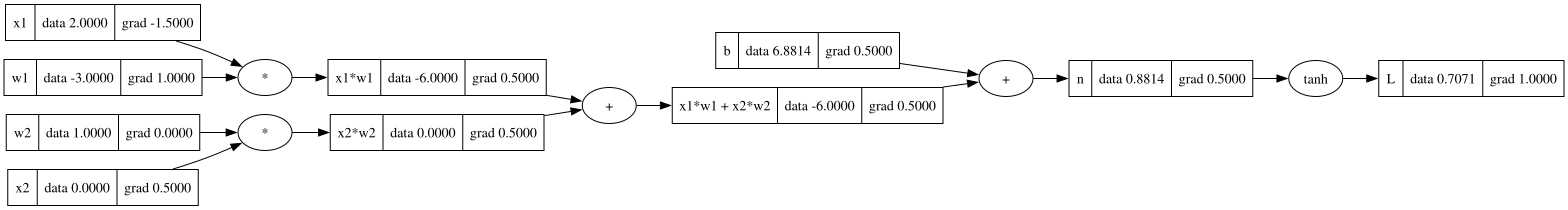

In [65]:
draw_dot(L)

---
# Part 5: Automating backpropagation

Doing this by hand is clearly not going to scale to networks with thousands of nodes. Notice, though, that we kept repeating the **same small step** at every node: *"take my gradient, multiply by my operation's local derivative, add it to each of my children."*

That step is exactly what each `_backward()` closure inside the `Value` class does (look at `__add__`, `__mul__` and `tanh` above):

- `_backward()` does **one local step only**: it pushes **one** node's gradient to its **direct** children. It does *not* recurse through the whole graph.
- Each node's `_backward` was created and stored **during the forward pass**, at the moment that node was computed. That's why it "remembers" which children to update (a Python *closure* captures `self`, `other` and `out`).

So backprop = call `_backward()` on every node, starting from the output and moving backwards. First we'll do this by hand, node by node.

### Backpropagation by calling each node's `_backward()` manually

In [66]:
# Rebuild the same neuron from scratch.
# Creating fresh Value objects means all gradients start at 0 again (the old graph is discarded).

# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of the neuron
b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2' # Sum of weighted inputs
n = x1w1x2w2 + b; n.label = 'n'

L = n.tanh(); L.label = 'L' # Output of the neuron after applying tanh activation function

**Order matters.** We must call a node's `_backward()` only *after* its own `grad` is completely known, so we go from the output toward the inputs.

Also, `L.grad` must be set to `1.0` manually first: every `_backward` multiplies by `out.grad`, so if `L.grad` were left at 0, every gradient would come out as 0.

In [67]:
# End Node

L.grad = 1.0    # base case (otherwise everything below would be multiplied by 0)
L._backward()   # tanh step: fills n.grad = (1 - L^2) * L.grad = 0.5

In [68]:
n._backward()   # '+' step: copies n.grad into x1w1x2w2.grad and b.grad (both 0.5)

In [69]:
x1w1x2w2._backward()   # '+' step: copies 0.5 into x1w1.grad and x2w2.grad

In [70]:
x1w1._backward()   # '*' step: x1.grad = w1 * 0.5 = -1.5,  w1.grad = x1 * 0.5 = 1.0
x2w2._backward()   # '*' step: x2.grad = w2 * 0.5 =  0.5,  w2.grad = x2 * 0.5 = 0.0
# No need to call _backward() on the leaves (x1, w1, x2, w2, b): they have no children,
# so their default _backward does nothing.

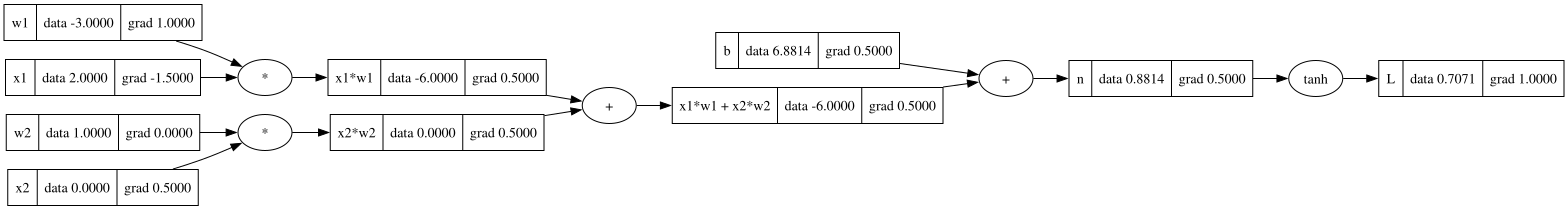

In [71]:
draw_dot(L)

Same gradients as the fully manual version. But we still had to figure out the **order** ourselves. Let's automate that too.

### Fully automatic: `backward()` with a topological sort

Now look at the `backward()` method (no underscore) at the bottom of the `Value` class. It automates the ordering we just did by hand, in three steps:

1. **Topological sort** (`build_topo`): a depth-first walk that adds a node to the `topo` list only **after all its children** have been added. So the list goes *inputs first … output last*.
   For our neuron it looks something like: `[x1, w1, x1*w1, x2, w2, x2*w2, x1*w1+x2*w2, b, n, L]`.
2. Set `self.grad = 1.0` (the base case $\frac{\partial L}{\partial L} = 1$).
3. Go through the list **in reverse** (output first) and call each node's `_backward()`.

Reversing a topological order guarantees that when we reach a node, **every node that uses it has already sent its gradient back**, so its `grad` is final before we pass it on. This matters when a node is used in more than one place.

Now a single call, `L.backward()`, does all of the work.

In [72]:
# Rebuild the neuron fresh (all grads = 0) ...

# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of the neuron
b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2' # Sum of weighted inputs
n = x1w1x2w2 + b; n.label = 'n'

L = n.tanh(); L.label = 'L' # Output of the neuron after applying tanh activation function
L.backward()  # ... and compute ALL gradients with a single call

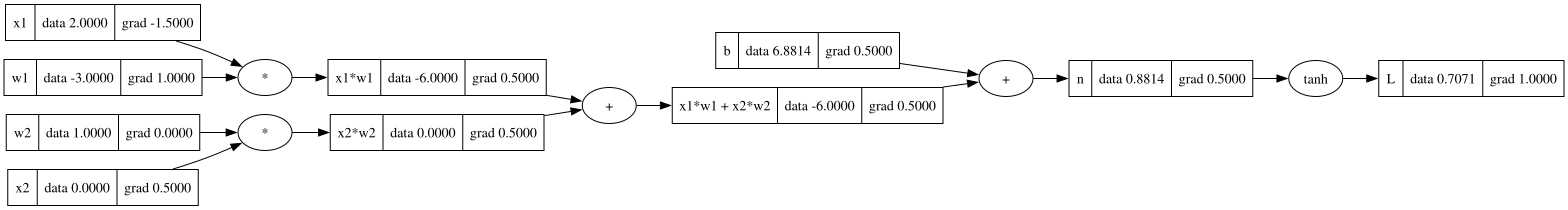

In [73]:
draw_dot(L)

### Breaking `tanh` into smaller operations

Instead of one `tanh` node with its own derivative, we can build tanh from more basic operations using its formula:

$$\tanh(n) = \frac{e^{2n} - 1}{e^{2n} + 1}$$

That's why the `Value` class also needed:
- `__rmul__` for `2 * n` (a plain number on the left),
- `exp()` with derivative $e^x$,
- `__sub__` / `__neg__` for `e - 1`,
- `__truediv__` (as `a * b**-1`) and `__pow__` (power rule) for the division.

**The point:** you can make operations as big or as small as you like. As long as each operation knows its **local derivative**, the chain rule stitches everything together and the final gradients are **identical**.

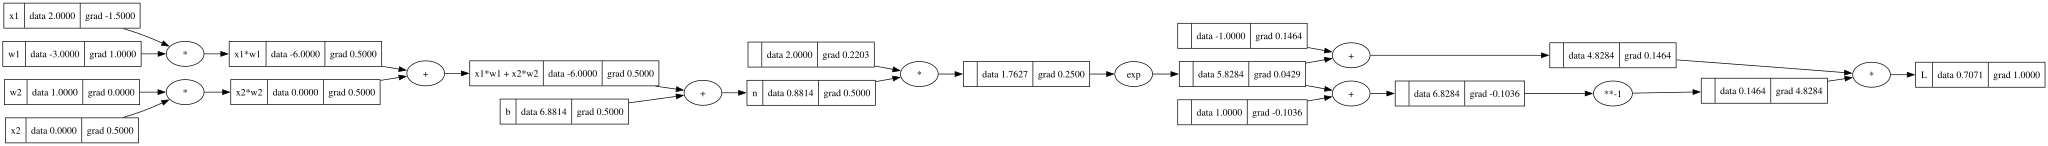

In [74]:
# Same neuron again, but with tanh written out "by hand" using exp, +, -, /

# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of the neuron
b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2' # Sum of weighted inputs
n = x1w1x2w2 + b; n.label = 'n'

# --- tanh(n) = (e^(2n) - 1) / (e^(2n) + 1), built from basic operations
e = (2*n).exp()      # 2*n uses __rmul__, then exp()
top = e - 1          # uses __sub__ -> __add__ + __neg__
bottom = e + 1       # uses __add__
L = top / bottom     # uses __truediv__ -> top * bottom**-1

#---

L.label = 'L' # Output of the neuron (same value as tanh(n): 0.7071)
L.backward()
draw_dot(L)   # bigger graph, but x1, w1, x2, w2, b end up with exactly the same grads as before

---
# Part 6: The same thing in PyTorch

micrograd is a miniature version of PyTorch's `autograd`. Here's the same neuron in PyTorch:

- `torch.tensor(...)` is like our `Value` (but a tensor can hold whole arrays, not just one number).
- `requires_grad=True` tells PyTorch to track operations on that tensor so it can compute its gradient. (Our `Value` always tracks.)
- `o.backward()` is like our `L.backward()`.
- `.grad` holds the gradient, and `.item()` pulls the plain Python number out of a one-element tensor.

The gradients match micrograd. The tiny differences (e.g. `-1.5000003` instead of `-1.5`) appear because PyTorch uses 32-bit floats (`float32`) by default, while Python floats are 64-bit. Adding `.double()` to each tensor would make them match exactly.

In [75]:
# Implementation in Pytorch

import torch

# Leaf tensors: requires_grad=True so PyTorch tracks them and computes their .grad
x1 = torch.tensor(2.0, requires_grad=True)
x2 = torch.tensor(0.0, requires_grad=True)
w1 = torch.tensor(-3.0, requires_grad=True)
w2 = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(6.8813735870195432, requires_grad=True)

# Forward pass (PyTorch builds the computation graph behind the scenes, like our Value class)
n = x1 * w1 + x2 * w2 + b
o = torch.tanh(n)

# Backward pass: fills .grad for every tensor with requires_grad=True
o.backward()

print(o.item())                        # 0.7071 (same as micrograd)
print("x1.grad:", x1.grad.item())      # -1.5
print("x2.grad:", x2.grad.item())      #  0.5
print("w1.grad:", w1.grad.item())      #  1.0
print("w2.grad:", w2.grad.item())      #  0.0
print("b.grad:", b.grad.item())        #  0.5

0.7071067094802856
x1.grad: -1.5000003576278687
x2.grad: 0.5000001192092896
w1.grad: 1.000000238418579
w2.grad: 0.0
b.grad: 0.5000001192092896


---
# Part 7: Building a neural network library on top of micrograd

Now we stack neurons into a network, using three small classes that each build on the previous one:

| Class | What it is | Contains |
|---|---|---|
| `Neuron(nin)` | one neuron with `nin` inputs | `nin` weights + 1 bias |
| `Layer(nin, nout)` | `nout` independent neurons, all seeing the **same** inputs | a list of `Neuron`s |
| `MLP(nin, nouts)` | **M**ulti-**L**ayer **P**erceptron: layers chained one after another | a list of `Layer`s |

Each class has:
- `__call__`, which lets you use the object like a function: `neuron(x)`, `layer(x)`, `mlp(x)` run the forward pass.
- `parameters()`, which returns all learnable `Value`s (weights and biases) so the training loop can update them.

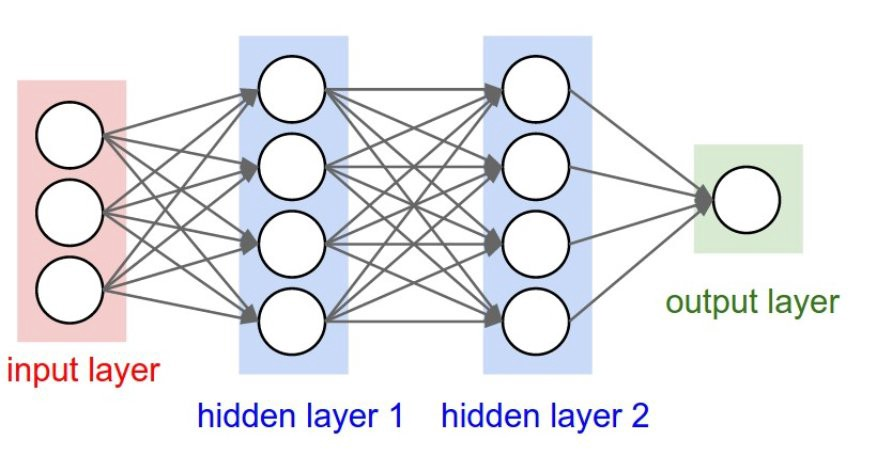

The picture above is exactly the network created below by `MLP(3, [4, 4, 1])`:
- **3 inputs** (input layer; these are just the data, not neurons)
- **hidden layer 1:** 4 neurons, each with 3 weights + 1 bias, so 4 × 4 = **16** parameters
- **hidden layer 2:** 4 neurons, each with 4 weights + 1 bias, so 4 × 5 = **20** parameters
- **output layer:** 1 neuron with 4 weights + 1 bias = **5** parameters

That's **41 parameters** in total, all `Value` objects, so backprop works through the whole network automatically. (You can check with `len(l.parameters())`.)

Every arrow in the diagram is one weight. Every neuron in a layer is connected to **every** output of the previous layer ("fully connected").

In [76]:
import random

class Neuron:
  # A single neuron: out = tanh(w1*x1 + w2*x2 + ... + b)

  def __init__(self, nin):
    # nin = number of inputs to this neuron
    # One random weight per input, initialised uniformly in [-1, 1].
    # (Random init matters: if all neurons started identical they would all learn the same thing.)
    self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1, 1))  # one bias per neuron

  def __call__(self, x):
    # Forward pass. x is a list of inputs (plain numbers or Values).
    # zip pairs each weight with its input; sum(..., self.b) STARTS the sum at the bias,
    # so this computes w1*x1 + w2*x2 + ... + b in one line.
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()  # non-linear activation
    return out

  def parameters(self):
    return self.w + [self.b]  # all weights followed by the bias

class Layer:
  # A layer is a list of independent neurons that all receive the SAME inputs

  def __init__(self, nin, nout):
    # nin = inputs per neuron, nout = number of neurons (= number of outputs of this layer)
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    out = [n(x) for n in self.neurons]       # run every neuron on the same input
    return out[0] if len(out) == 1 else out  # convenience: unwrap a single output (for the final layer)

  def parameters(self):
    # Flatten the parameters of every neuron into a single list
    return [p for neuron in self.neurons for p in neuron.parameters()]
    # params = []
    # for neuron in self.neurons:
    #   ps = neuron.parameters()
    #   params.extend(ps)
    # return params

class MLP:
  # Multi-Layer Perceptron: a chain of layers, where each layer's outputs are the next layer's inputs

  def __init__(self, nin, nouts):
    # nin = number of inputs, nouts = list of layer sizes, e.g. [4, 4, 1]
    sz = [nin] + nouts   # e.g. [3, 4, 4, 1]
    # Layer i maps sz[i] inputs -> sz[i+1] outputs: Layer(3,4), Layer(4,4), Layer(4,1)
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    # Forward pass: feed the output of each layer into the next one
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]
    # params = []
    # for layer in self.layers:
    #   ps = layer.parameters()
    #   params.extend(ps)
    # return params

In [77]:
x = [2.0, 3.0]          # NOTE: only 2 values, but the MLP below expects 3 inputs (see note below)
l = MLP(3, [4, 4, 1])   # 3 inputs -> 4 neurons -> 4 neurons -> 1 output
out = l(x)              # forward pass through the whole network
out                     # a single Value somewhere in (-1, 1); random, because the weights are random

Value(data=0.7864166370469831, label=)

> **Small gotcha:** the MLP was created for **3** inputs but `x` only has **2**. Python doesn't complain because `zip(self.w, x)` silently stops at the shorter list, so each first-layer neuron just ignores its third weight. It works, but it's almost certainly not what was intended. `x = [2.0, 3.0, -1.0]` would match the network properly.
>
> Also note the network is named **`l`**; that same network object is the one trained below.

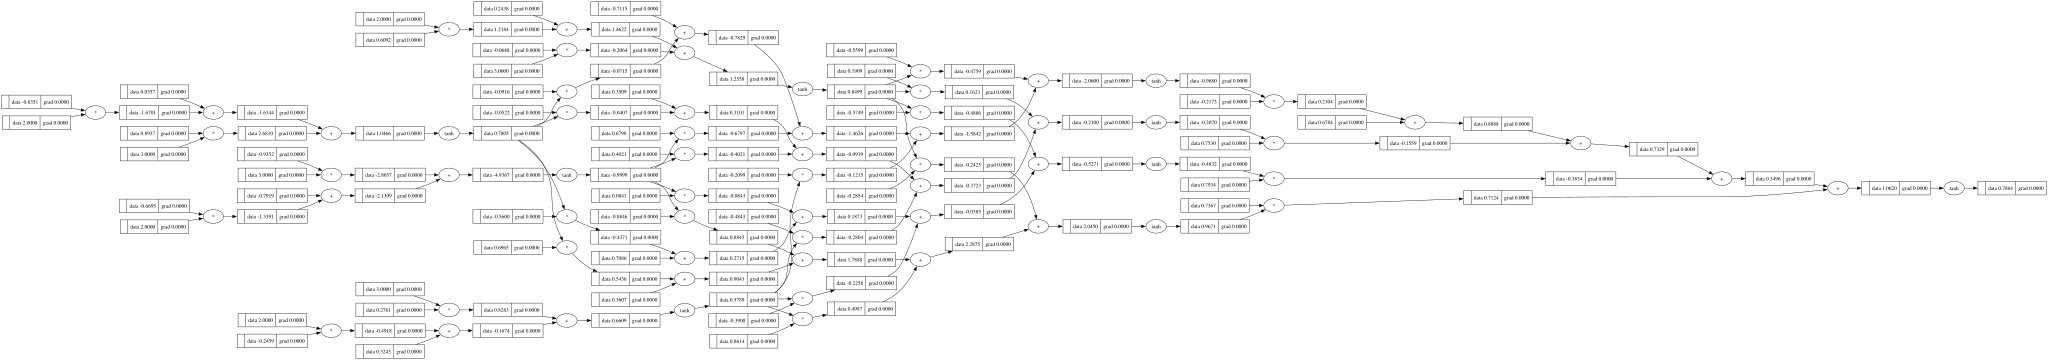

In [78]:
draw_dot(out)

That's the full computation graph for **one** forward pass of a tiny network: every multiply, add and tanh is a node. Calling `out.backward()` would compute the gradient of the output with respect to every single one of those nodes, including all 41 parameters.

---
# Part 8: Training the network (gradient descent)

### The dataset

4 examples, each with 3 input features, plus the desired output (**target**) for each. Think of it as a tiny binary classifier: we want the network to output **+1.0** for examples 1 and 4, and **-1.0** for examples 2 and 3.

In [79]:
# Creating a sample dataset for training the MLP model.

# input values: 4 examples x 3 features each
xs = [
  [2.0, 3.0, -1.0],   # should output  1.0
  [3.0, -1.0, 0.5],   # should output -1.0
  [0.5, 1.0, 1.0],    # should output -1.0
  [1.0, 1.0, -1.0]    # should output  1.0
]

# desired targets ("ground truth", gt)
ys = [1.0, -1.0, -1.0, 1.0]

### The training loop

Every iteration has four steps:

1. **Forward pass:** run all 4 examples through the network to get predictions `ypred`.
2. **Loss:** a single number measuring *how wrong* the predictions are. We use the **sum of squared errors**:
   $$\text{loss} = \sum_i (\text{ypred}_i - \text{y}_i)^2$$
   Squaring makes every error positive and punishes big errors more. The loss is 0 only when every prediction exactly equals its target. Because `loss` is a `Value`, it's the root of one big computation graph that contains every parameter.
3. **Backward pass:**
   - **Zero the gradients first!** `_backward` uses `+=`, so without this, gradients from the previous iteration would pile up and the updates would be wrong. (This is a very common bug, even in PyTorch, where you call `optimizer.zero_grad()`.)
   - `loss.backward()` then fills `p.grad` for all 41 parameters: *how would the loss change if I nudged this parameter up?*
4. **Update (gradient descent):** `p.data += -0.01 * p.grad`
   - The **minus sign** moves each parameter *against* its gradient, so the loss goes **down** (the opposite of the "nudge" experiment in Part 3, where we made `L` go up).
   - `0.01` is the **learning rate** (step size). Too large and training jumps around or diverges; too small and it's very slow.

Repeat many times and the loss steadily shrinks.

> Tip: printing all 10,000 steps creates a very long output. `if step % 1000 == 0: print(step, loss.data)` would print only every 1000th step.

In [81]:
# Gradient Descent

for step in range(10000):
  # 1) Forward Pass: predictions for all 4 examples
  ypred = [l(x) for x in  xs]
  # 2) Loss: sum of squared errors between each prediction (yout) and its target (ygt = "ground truth")
  loss = sum([(yout-ygt)**2 for ygt, yout in zip(ys, ypred)])

  # 3) Backward Pass
  for param in l.parameters(): # Reset every gradient to 0 before each backward pass,
    param.grad = 0             # because _backward ACCUMULATES with += (old gradients would pile up)
  loss.backward()              # compute d(loss)/d(param) for every weight and bias

  # 4) Update: step each parameter a little AGAINST its gradient (minus sign) so the loss decreases
  for p in l.parameters():
    p.data += -0.01*p.grad     # 0.01 = learning rate

  print(step, loss)  # loss should shrink over time

0 Value(data=0.0021111109801925246, label=)
1 Value(data=0.0021099808673634753, label=)
2 Value(data=0.002108851912171342, label=)
3 Value(data=0.0021077241128698108, label=)
4 Value(data=0.002106597467716059, label=)
5 Value(data=0.0021054719749707272, label=)
6 Value(data=0.0021043476328978994, label=)
7 Value(data=0.0021032244397651218, label=)
8 Value(data=0.0021021023938433874, label=)
9 Value(data=0.0021009814934071012, label=)
10 Value(data=0.0020998617367341227, label=)
11 Value(data=0.002098743122105684, label=)
12 Value(data=0.002097625647806465, label=)
13 Value(data=0.002096509312124516, label=)
14 Value(data=0.0020953941133513036, label=)
15 Value(data=0.0020942800497816393, label=)
16 Value(data=0.0020931671197137523, label=)
17 Value(data=0.002092055321449211, label=)
18 Value(data=0.002090944653292942, label=)
19 Value(data=0.0020898351135532293, label=)
20 Value(data=0.002088726700541687, label=)
21 Value(data=0.0020876194125732735, label=)
22 Value(data=0.002086513247

In [82]:
# Final predictions after training: compare with the targets ys = [1.0, -1.0, -1.0, 1.0]
ypred

[Value(data=0.9929033537798592, label=),
 Value(data=-0.992154961677562, label=),
 Value(data=-0.9896494872175641, label=),
 Value(data=0.9906552351090446, label=)]

### Result

The loss dropped from about **5.27** to about **0.0004**, and the predictions are now very close to the targets:

| Target | Prediction |
|---|---|
| 1.0 | 0.997 |
| -1.0 | -0.987 |
| -1.0 | -0.992 |
| 1.0 | 0.988 |

The network has learned to map each input to its desired output. Your exact numbers will differ each run because the weights start out random.

---
# Recap: the whole idea in a few lines

1. **A derivative** says how much the output moves when you nudge an input.
2. **`Value`** wraps each number and records how it was computed, building a **computation graph** during the forward pass.
3. Each operation knows only its **local derivative**. The **chain rule** (multiply local derivative × gradient from above) carries gradients backwards through the graph.
4. **`backward()`** topologically sorts the graph and applies every node's `_backward()` from the output to the inputs.
5. **A neural network** is just a big expression of `Value`s (neurons → layers → MLP).
6. **Training** = forward pass → loss → zero grads → backward pass → step parameters against their gradients, and repeat.

That's essentially everything PyTorch does too. It just does it on large tensors (many numbers at once) with very efficient code.

### Things to try
- Change the learning rate (e.g. `0.1` or `0.001`) and watch how quickly the loss falls, or whether it blows up.
- Comment out the gradient-zeroing loop and see what happens to training.
- Fix the input-size gotcha (`x = [2.0, 3.0, -1.0]`) and re-run.
- Add a `relu()` method to `Value` (forward: `max(0, x)`; local derivative: `1 if x > 0 else 0`) and use it in `Neuron` instead of `tanh`.